---
tags: [algorithm, encoding, resource-estimation]
---

# Quantum Singular Value Transformation

Quantum singular value transformation (QSVT) {cite:p}`10.1145/3313276.3316366`
applies a polynomial to the singular values of a matrix embedded in a larger
unitary. In this article, we construct a block encoding of a non-Hermitian
$2\times2$ matrix, apply the degree-two Chebyshev polynomial with `qsvt`,
and verify the transformed matrix and logical resource estimate.

In [1]:
# Install the latest Qamomile through pip!
# !pip install "qamomile[qiskit]" matplotlib

In [2]:
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import Operator

import qamomile as qm
from qamomile.linalg import decompose_pauli_matrix
from qamomile.qiskit import Aer, Qiskit, to_circuit
from qamomile.stdlib import QSVTPhases, pauli_block_encoding, qsvt

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
SAMPLE_SHOTS = 1 if docs_test_mode else 32

## Background

### Quantum signal processing (QSP)

Quantum signal processing (QSP) {cite:p}`10.1103/PhysRevLett.118.010501`
transforms a scalar value $x\in[-1,1]$ encoded in a single-qubit unitary by a
polynomial. QSP is constructed as an alternating product of signal unitaries
and phase rotations. In one common convention, the signal unitary is

$$
W(x)=e^{i\arccos(x)X}
=\begin{pmatrix}
x & i\sqrt{1-x^2}\\
i\sqrt{1-x^2} & x
\end{pmatrix}.
$$

Between signal unitaries, QSP applies controllable $Z$-axis phase rotations

$$
S(\phi)=e^{i\phi Z}
=\operatorname{diag}(e^{i\phi},e^{-i\phi}).
$$

A phase sequence $\Phi=(\phi_0,\phi_1,\ldots,\phi_d)$ defines the alternating
product

$$
U_\Phi(x)
=S(\phi_0)\prod_{j=1}^{d}\left(W(x)S(\phi_j)\right).
$$

The upper-left entry $\langle0|U_\Phi(x)|0\rangle=P_\Phi(x)$ is a polynomial
in $x$. A real target polynomial $p(x)$ can be represented as
$\operatorname{Re}[P_\Phi(x)]$ when it satisfies the following conditions:

- Its degree is at most $d$.
- Its parity matches $d$: $p(-x)=(-1)^d p(x)$.
- It is bounded on the signal interval: $|p(x)|\leq1$ for $x\in[-1,1]$.

QSP design first approximates a target function $p(x)$ by such a polynomial
and then classically synthesizes the corresponding phases. A degree-$d$
transformation uses $d$ calls to the signal unitary, so the polynomial degree
determines the query complexity.

QSVT lifts this scalar polynomial transformation to each singular-value
subspace of a block-encoded matrix.

### Block encoding

Before extending QSP to the singular-value subspaces of a matrix, we first
explain how quantum computation handles non-unitary matrices. Block encoding
embeds a given (non-unitary) matrix as part of a larger unitary matrix.

Let $A$ act on an $n$-qubit system register. An $(\alpha,a)$ block encoding
is a unitary $U$ acting on an additional $a$-qubit signal register such that

$$
(\langle 0|^{\otimes a}\otimes I)U
(|0\rangle^{\otimes a}\otimes I)=\frac{A}{\alpha}.
$$

Here, $\alpha$ is a normalization factor satisfying
$\alpha\geq\lVert A\rVert_2$. The encoded block is therefore $A/\alpha$, so
QSVT acts on singular values in the interval $[0,1]$. The value of $\alpha$
determines the scaling between the polynomial implemented by the circuit and
the function ultimately applied to $A$.

Block encoding converts a generally non-unitary matrix operation into part
of a unitary evolution. Projecting the signal register onto
$|0\rangle^{\otimes a}$ before and after $U$ selects the encoded matrix block.
This interface lets QSVT manipulate the singular values without requiring
the matrix itself to be unitary or Hermitian.

Common ways to construct a block encoding include:

- **Sparse-access oracles**: for a sparse matrix, coherent oracles provide the
  locations and values of its nonzero entries. These oracles can be combined
  into a unitary whose projected block is the normalized sparse matrix.
- **Linear combination of unitaries (LCU)**: when
  $A=\sum_j c_j U_j$ is expressed as a weighted sum of efficiently
  implementable unitaries, an auxiliary register selects $U_j$ with an
  amplitude determined by $c_j$. Projecting that register produces
  $A/\sum_j|c_j|$.

Block encodings can also be constructed from state-preparation procedures or
data stored in quantum read-only memory.

## Algorithm

Let $U$ be an $(\alpha,a)$ block encoding of a matrix with singular value
decomposition

$$
A=W\Sigma V^\dagger,
$$

and define the projector onto the signal subspace as

$$
\Pi=|0\rangle\!\langle0|^{\otimes a}\otimes I.
$$

A phase-modulated reflection about this subspace can be written as

$$
R_\Pi(\phi)=\exp\!\left(i\phi(2\Pi-I)\right).
$$

QSVT alternates applications of $U$ and $U^\dagger$ with these phase
rotations. For a phase sequence

$$
\Phi=(\phi_0,\phi_1,\ldots,\phi_d),
$$

the resulting product acts independently on the two-dimensional invariant
subspace associated with each singular value $\sigma_j/\alpha$. Choosing the
phases appropriately makes the projected response equal to a polynomial
$P(\sigma_j/\alpha)$.

The parity of $P$ determines how the left and right singular-vector spaces
are connected. With the singular value decomposition above, the singular
value transform is

$$
P^{(\mathrm{SV})}(A/\alpha)=
\begin{cases}
W P(\Sigma/\alpha)V^\dagger, & P\text{ odd},\\
V P(\Sigma/\alpha)V^\dagger, & P\text{ even}.
\end{cases}
$$

A QSVT algorithm therefore consists of the following steps:

1. Choose a normalized block encoding of the input matrix.
2. Approximate the target scalar function by a bounded polynomial with the
   required parity.
3. Classically synthesize a phase sequence for that polynomial.
4. Apply the alternating sequence of block encodings, their adjoints, and
   projector phase rotations.
5. Project onto the signal subspace to obtain the desired singular-value
   transformation.

Different QSP/QSVT references and implementations may define the phases and
order the operations differently. A phase sequence synthesized under one
convention must therefore be used in a circuit that follows the same
convention.

## Qamomile implementation

In this section, we use LCU to construct a block encoding of a non-Hermitian
matrix and build a Qamomile quantum kernel that applies QSVT to it. We then
convert it to the Qiskit circuit used for the numerical validation.

### Problem setup

Consider the following non-Hermitian matrix:

In [3]:
matrix = np.array([[0.0, 1.0], [0.0, 0.0]], dtype=complex)

In the computational basis, this matrix maps $|1\rangle$ to $|0\rangle$ and
maps $|0\rangle$ to the zero vector. It is neither unitary nor Hermitian, so
it cannot be applied directly as a quantum gate. QSVT instead works with a
unitary whose projected block is the normalized matrix $A/\alpha$. The small
matrix keeps that projection easy to inspect while exercising the same
block-encoding and QSVT interfaces used for larger matrices.

### Constructing the block encoding

Linear combination of unitaries (LCU) is one way to construct a block
encoding. It decomposes the target matrix into a weighted sum of unitaries
and uses an auxiliary register to select them, embedding the sum in a larger
unitary circuit. Specifically, LCU represents the matrix as

$$
A=\sum_j c_j U_j,
\qquad
\alpha=\sum_j|c_j|,
$$

where each $U_j$ is unitary. PREPARE creates the selector state

$$
\operatorname{PREPARE}|0\rangle
=\sum_j\sqrt{\frac{|c_j|}{\alpha}}|j\rangle,
$$

and SELECT applies $e^{i\arg(c_j)}U_j$ conditioned on $|j\rangle$. The
sequence PREPARE--SELECT--UNPREPARE then has $A/\alpha$ as its all-zero
selector block.

Here, `decompose_pauli_matrix` chooses Pauli words for the unitaries $U_j$ and
computes their complex coefficients. `pauli_block_encoding` builds
the corresponding LCU block encoding. The returned descriptor records the
normalization and the widths of the signal and system registers; Qamomile
uses this metadata when the block encoding is inserted into a quantum
kernel.

In [4]:
decomposition = decompose_pauli_matrix(matrix, atol=0.0)
block_encoding = pauli_block_encoding(decomposition.operator)

print("Pauli terms:", decomposition.num_terms)
print("normalization:", block_encoding.normalization)
print("signal qubits:", block_encoding.signal_width)
print("system qubits:", block_encoding.system_width)

assert decomposition.truncation_error_bound == 0.0
assert decomposition.num_terms == 2
assert np.isclose(block_encoding.normalization, 1.0)
assert block_encoding.signal_width == 1
assert block_encoding.system_width == 1

Pauli terms: 2
normalization: 1.0
signal qubits: 1
system qubits: 1


For this matrix, the Pauli expansion is
$A=(X+iY)/2$. Therefore, the LCU has two terms and normalization
$\alpha=|1/2|+|i/2|=1$. One signal qubit selects between those two terms,
while one system qubit carries the state on which $A$ acts. The assertions
above make these structural properties explicit before the descriptor is
passed to QSVT.

### Defining the quantum kernels

`BlockEncoding` carries a unary coherent callable over the joint signal and
system register. `qsvt` closes that callable and the phases into an ordinary
Qamomile helper. Its quantum input and output have the same owned shape;
measurement belongs in a caller that needs samples.

In the scalar `Wx` convention, three zero phases implement $T_2(x)=2x^2-1$.
`QSVTPhases.from_qsp_wx` converts those coordinates to the projector convention
used by `qsvt`. Conversion alone makes no approximation certificate; the
projected-matrix check below verifies this particular phase sequence.

In [5]:
qsp_phases = (0.0, 0.0, 0.0)
qsvt_phases = QSVTPhases.from_qsp_wx(qsp_phases, odd=False)
transform = qsvt(block_encoding, phases=qsvt_phases)
total_width = block_encoding.total_width
signal_width = block_encoding.signal_width


@qm.qkernel
def singular_value_transform() -> qm.Q[qm.Bits[total_width]]:
    """Apply the configured QSVT sequence and retain the complete state."""
    return transform(qm.qubits(total_width))


program = singular_value_transform.specialize()

### Constructing the QSVT circuit

Specialize the coherent state preparation and inspect its Qiskit circuit with
`to_circuit`. The same verified program supplies the unitary check and
logical resource study. Projector rotations act directly on the
signal subspace: this implementation uses two qubits without a separate
projector workspace qubit. The program retains the coherent state, so its
circuit has no final measurements to remove before the numerical check.
Compilation for execution requires a classical result; the measured caller
below supplies that boundary.

In [6]:
target = Qiskit(optimization_level=0, seed_transpiler=7)
qsvt_circuit = to_circuit(program, target=target)
assert qsvt_circuit.num_qubits == total_width == 2

## Result

Extract the all-zero signal block of the complete QSVT unitary and compare it
with $2(A/\alpha)^\dagger(A/\alpha)-I$. The formulas above write the signal
register first. In the circuit, the signal is qubit 0 and the system is
qubit 1. Qiskit's matrix labels $|b_1 b_0\rangle$ put the signal on the
right, so signal zero selects rows and columns 0 and 2.

In [7]:
def projected_signal_block(
    unitary: np.ndarray,
    signal_width: int,
    system_width: int,
) -> np.ndarray:
    """Select all-zero low-order signal wires in Qiskit's matrix convention.

    Args:
        unitary (np.ndarray): Complete circuit unitary in SDK bit order.
        signal_width (int): Number of leading logical signal wires.
        system_width (int): Number of remaining logical system wires.

    Returns:
        np.ndarray: Matrix block acting on the system register.
    """
    projected_indices = np.arange(1 << system_width) << signal_width
    return unitary[np.ix_(projected_indices, projected_indices)]


qsvt_unitary = np.asarray(Operator(qsvt_circuit).data)
actual_transform = projected_signal_block(
    qsvt_unitary, block_encoding.signal_width, block_encoding.system_width
)
normalized_matrix = matrix / block_encoding.normalization
expected_transform = 2.0 * normalized_matrix.conj().T @ normalized_matrix - np.eye(
    1 << block_encoding.system_width
)
np.testing.assert_allclose(actual_transform, expected_transform, rtol=0.0, atol=1e-12)
print("QSVT projected block:\n", np.round(actual_transform, decimals=8))

QSVT projected block:
 [[-1.+0.j  0.+0.j]
 [ 0.+0.j  1.-0.j]]


### Executing the same transform

Here the projected transform is $\operatorname{diag}(-1,1)$. Prepare the system
in $|+\rangle$, apply the transform, and read its relative phase with a second
Hadamard. Every shot must retain the zero signal and return system bit one.
Compile and execute this sampler through the current lifecycle, comparing the
local Aer endpoint with the same source on `Reference`.

In [8]:
@qm.qkernel
def interference_sample() -> qm.Shot[qm.Bits[total_width]]:
    """Read the transformed system's relative phase through interference."""
    state = qm.h(qm.qubits(total_width), target=signal_width)
    state = transform(state)
    state = qm.h(state, target=signal_width)
    return qm.measure(state)


endpoint = Aer(optimization_level=0, seed_transpiler=7)
sample_program = interference_sample.specialize()
sample_artifact = qm.compile(sample_program, to=endpoint.target)
record = qm.run(sample_artifact, on=endpoint, shots=SAMPLE_SHOTS, seed=7)
reference = qm.run(sample_program, on=qm.Reference(), shots=SAMPLE_SHOTS, seed=7)
assert record.result.counts == reference.result.counts == {(0, 1): SAMPLE_SHOTS}
print("signal/system samples:", record.result.counts)

signal/system samples: {(0, 1): 32}


The two singular values of $A$ are $1$ and $0$. The polynomial maps them to
$1$ and $-1$, respectively, exactly as observed in the projected block.

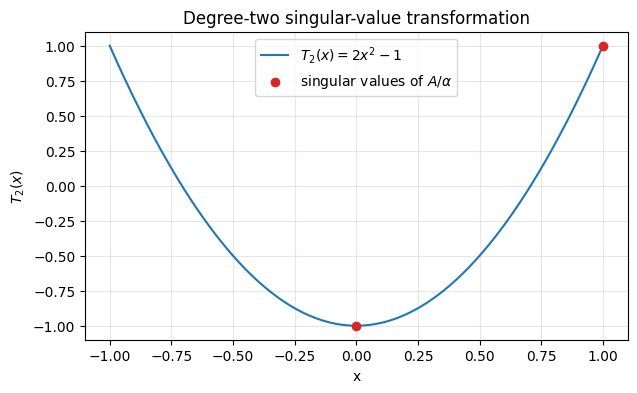

In [9]:
polynomial_x = np.linspace(-1.0, 1.0, 3 if docs_test_mode else 400)
polynomial_y = 2.0 * polynomial_x**2 - 1.0
singular_values = np.linalg.svd(normalized_matrix, compute_uv=False)
transformed_singular_values = 2.0 * singular_values**2 - 1.0

fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(polynomial_x, polynomial_y, label=r"$T_2(x)=2x^2-1$")
axis.scatter(
    singular_values,
    transformed_singular_values,
    color="tab:red",
    zorder=3,
    label=r"singular values of $A/\alpha$",
)
axis.set_xlabel("x")
axis.set_ylabel("$T_2(x)$")
axis.set_title("Degree-two singular-value transformation")
axis.grid(alpha=0.3)
axis.legend()
plt.show()

## Resource estimation

### Query complexity

The QSVT circuit construction by Gilyén et al.
{cite:p}`10.1145/3313276.3316366` (Section 3.2 and Figure 1) uses $U$ and
$U^\dagger$ a total of $d$ times and applies $d+1$ projector phase rotations
for a degree-$d$ transformation. The query complexity to the block encoding
is therefore $\Theta(d)$. The required degree depends on the target function,
approximation interval, allowed error, and normalization $\alpha$.

If $U$ and $U^\dagger$ have the same cost $G_U$, and one projector phase
rotation costs $G_\Pi(a)$, the gate cost excluding measurement and other
post-processing can be organized as

$$
G_{\mathrm{QSVT}}\simeq dG_U+(d+1)G_\Pi(a).
$$

The first term counts block-encoding calls, and the second counts projector
phase rotations. This is a cost breakdown of the cited circuit construction,
not a universal backend gate count: $G_U$ depends on whether the block
encoding uses LCU, sparse oracles, or another construction, while $G_\Pi(a)$
depends on the decomposition of multi-controlled gates.


### Logical resources for this example

`qm.resources.logical` analyzes the verified source program. Each metric has
a relation, bounds, evidence, and named unknown contributors. Keep the
distinction between a proved width and a partial gate/depth enclosure.

In [10]:
study = qm.resources.logical(program)
peak = study.metric(qm.resources.LOGICAL_PEAK_QUBITS)
gates = study.metric(qm.resources.LOGICAL_GATES)
depth = study.metric(qm.resources.LOGICAL_GATE_DEPTH)

print("logical peak qubits:", peak)
print("logical gates:", gates)
print("logical depth:", depth)
for reason in gates.unknown_contributors:
    print("unresolved gate contribution:", reason)

assert peak.numeric_enclosure() == (total_width, total_width) == (2, 2)
assert len(qsvt_phases.phases) - 1 == 2
assert gates.numeric_enclosure()[0] > 0

logical peak qubits: = 2 logical_qubits
logical gates: in [8, ?] semantic_operations; unknown: body-backed controlled transform of __main__._scalar_phase has no exact gate-family or dependency-span profile, body-backed controlled transform of __main__.apply_x__852fb1637ab6, __main__.phased__ee60596bf380 has no exact gate-family or dependency-span profile
logical depth: in [1, ?] dependency_steps; unknown: body-backed controlled transform of __main__._scalar_phase has no exact gate-family or dependency-span profile, body-backed controlled transform of __main__.apply_x__852fb1637ab6, __main__.phased__ee60596bf380 has no exact gate-family or dependency-span profile
unresolved gate contribution: body-backed controlled transform of __main__._scalar_phase has no exact gate-family or dependency-span profile
unresolved gate contribution: body-backed controlled transform of __main__.apply_x__852fb1637ab6, __main__.phased__ee60596bf380 has no exact gate-family or dependency-span profile


Peak live width is exactly two: one signal and one system qubit. The degree
is two, so the construction uses one query to $U$, one to $U^\dagger$, and three
projector rotations.

The logical gate and depth metrics report unresolved controlled-call costs
for this source. Their finite lower endpoints are not complete gate counts;
the unknown contributors printed above cannot be treated as zero. Backend
decomposition and scheduling can be studied for a selected target separately
from the mathematical block-query count.

## Summary

In this article, we:

- constructed a Pauli LCU block encoding of a non-Hermitian matrix;
- confirmed the degree-two transform $2(A/\alpha)^\dagger(A/\alpha)-I$ by matrix
  projection and deterministic execution on Aer and `Reference`; and
- compared the mathematical query count with the proved logical width and
  partial gate/depth metrics of the same verified program.

`QSVTPhases.from_qsp_wx` converts phase coordinates. For other real target
polynomials, `synthesize_qsvt_polynomial` returns a Rust-verified certificate
that can be supplied through `qsvt(encoding, polynomial=...)`. Approximation
domains and downstream error requirements remain part of the algorithm design.